# Experiment 6: A simple neural network (XOR from scratch)
**Aim.** To implement a two-layer neural network in NumPy alone, train it on XOR by backpropagation, and observe the
effect of the learning rate.

## Theory (summary)
$h = \sigma(W_1x+b_1)$, $o = \sigma(W_2h+b_2)$, $E = \frac1N\sum(o-y)^2$

$\delta_o = (o-y)\,o(1-o)$, $\delta_h = (\delta_o W_2^\top)\,h(1-h)$

In [1]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
os.makedirs('figs', exist_ok=True)
plt.rcParams['figure.dpi'] = 110

## Example 1: Forward pass and loss

In [2]:
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0],   [1],   [1],   [0]  ], dtype=float)   # XOR

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

rng = np.random.default_rng(1)
hidden = 4
W1 = rng.normal(0, 1, (2, hidden)); b1 = np.zeros((1, hidden))
W2 = rng.normal(0, 1, (hidden, 1)); b2 = np.zeros((1, 1))

h = sigmoid(X @ W1 + b1)        # hidden activations, 4 x hidden
o = sigmoid(h @ W2 + b2)        # output, 4 x 1
print('initial loss:', float(np.mean((o - y)**2)))

initial loss: 0.2748629616482994


### Why a single linear unit cannot represent XOR

In [3]:
w = rng.normal(0, 1, (2, 1)); b = np.zeros((1, 1))
for _ in range(20000):
    o1 = sigmoid(X @ w + b)
    d = (o1 - y) * o1 * (1 - o1)
    w -= 2.0 * X.T @ d; b -= 2.0 * d.sum(0, keepdims=True)
print('single unit outputs:', sigmoid(X @ w + b).ravel().round(3),
      ' MSE =', round(float(np.mean((sigmoid(X @ w + b) - y)**2)), 4))
print('-> stuck near 0.25 MSE: no straight line separates XOR')

single unit outputs: [0.5 0.5 0.5 0.5]  MSE = 0.25
-> stuck near 0.25 MSE: no straight line separates XOR


## Example 2: Backpropagation and training

In [4]:
def train_xor(lr, epochs=20000, seed=1, hidden=4, zero_init=False):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, 1, (2, hidden)); b1 = np.zeros((1, hidden))
    W2 = rng.normal(0, 1, (hidden, 1)); b2 = np.zeros((1, 1))
    if zero_init:
        W1[:] = 0; W2[:] = 0
    loss = []
    for _ in range(epochs):
        h = sigmoid(X @ W1 + b1)                  # forward
        o = sigmoid(h @ W2 + b2)
        loss.append(float(np.mean((o - y)**2)))

        do = (o - y) * o * (1 - o)                # backward
        dW2 = h.T @ do; db2 = do.sum(0, keepdims=True)
        dh = (do @ W2.T) * h * (1 - h)
        dW1 = X.T @ dh; db1 = dh.sum(0, keepdims=True)

        W2 -= lr*dW2; b2 -= lr*db2                # gradient descent
        W1 -= lr*dW1; b1 -= lr*db1
    return (W1, b1, W2, b2), np.array(loss)

params, loss = train_xor(2.0)
W1, b1, W2, b2 = params
print('final loss:', loss[-1])
print('predictions:', sigmoid(sigmoid(X @ W1 + b1) @ W2 + b2).ravel().round(3))

final loss: 2.455286480396732e-05
predictions: [0.004 0.995 0.996 0.006]


### Zero initialisation: hidden units stay identical

In [5]:
pz, lz = train_xor(2.0, zero_init=True)
print('final loss with zero init:', round(lz[-1], 4))
print('hidden-unit weight columns (all identical):\n', pz[0].round(4))

final loss with zero init: 0.25
hidden-unit weight columns (all identical):
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]]


## Example 3: Learning rate and the decision boundary

lr=0.05: final MSE = 2.31e-03


lr=0.5: final MSE = 1.11e-04


lr=2.0: final MSE = 2.46e-05


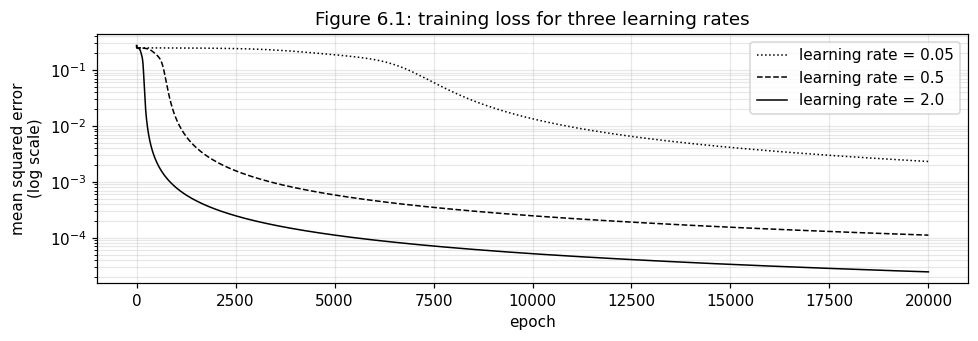

In [6]:
plt.figure(figsize=(9, 3.2))
final = {}
for lr, ls in ((0.05, ':'), (0.5, '--'), (2.0, '-')):
    _, l = train_xor(lr)
    final[lr] = l[-1]
    plt.semilogy(l, ls, lw=1.0, color='k', label=f'learning rate = {lr}')
    print(f'lr={lr}: final MSE = {l[-1]:.2e}')
plt.xlabel('epoch'); plt.ylabel('mean squared error\n(log scale)'); plt.legend()
plt.title('Figure 6.1: training loss for three learning rates')
plt.grid(alpha=0.3, which='both'); plt.tight_layout(); plt.savefig('figs/fig6_1_loss.png'); plt.show()

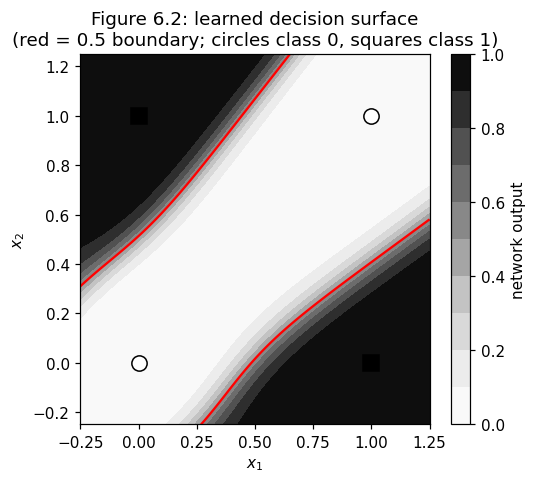

In [7]:
gx, gy = np.meshgrid(np.linspace(-0.25, 1.25, 300),
                     np.linspace(-0.25, 1.25, 300))
G = np.c_[gx.ravel(), gy.ravel()]
Z = sigmoid(sigmoid(G @ W1 + b1) @ W2 + b2).reshape(gx.shape)

plt.figure(figsize=(5, 4.5))
cs = plt.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11), cmap='Greys')
plt.contour(gx, gy, Z, levels=[0.5], colors='r')
plt.colorbar(cs, label='network output')
for (a, b_), t_ in zip(X, y.ravel()):
    plt.plot(a, b_, 'o' if t_ == 0 else 's', ms=10, mfc='white' if t_ == 0 else 'k', mec='k')
plt.xlabel('$x_1$'); plt.ylabel('$x_2$')
plt.title('Figure 6.2: learned decision surface\n(red = 0.5 boundary; circles class 0, squares class 1)')
plt.tight_layout(); plt.savefig('figs/fig6_2_boundary.png'); plt.show()

### Try learning rate 10.0 (as the manual asks)

In [8]:
for lr in (10.0, 50.0):
    p_, l_ = train_xor(lr)
    W1_, b1_, W2_, b2_ = p_
    preds = sigmoid(sigmoid(X @ W1_ + b1_) @ W2_ + b2_).ravel().round(3)
    print(f'lr={lr}: final MSE = {l_[-1]:.2e}, predictions = {preds}, '
          f'max loss jump = {np.max(np.diff(l_)):.2e}')

lr=10.0: final MSE = 5.81e-06, predictions = [0.002 0.998 0.998 0.003], max loss jump = 1.55e-01


lr=50.0: final MSE = 2.49e-01, predictions = [0.    0.999 0.999 0.999], max loss jump = 4.19e-01


In [9]:
print(f"{'Learning rate':>13} {'Final MSE':>11}  Converged?")
for lr, v in final.items():
    print(f'{lr:>13} {v:>11.2e}  {"yes" if v < 1e-3 else "no (still descending)"}')

Learning rate   Final MSE  Converged?
         0.05    2.31e-03  no (still descending)
          0.5    1.11e-04  yes
          2.0    2.46e-05  yes


## Observations to record
* Network: 2-4-1 with sigmoid activations, initialisation seed 1, 20 000 epochs.
* Learning rates tried: 0.05, 0.5, 2.0 and 10.0. The final MSE, the convergence verdict and the four predicted outputs are printed above.

## Discussion
* **Expected:** a single unit fails on XOR and a hidden layer succeeds. A larger learning rate converges faster until it becomes unstable.
* **Observed:** the single unit stays at MSE ≈ 0.25. The 2-4-1 network reaches predictions close to (0, 1, 1, 0).
  lr = 0.05 is still descending after 20 000 epochs, while 0.5 and 2.0 converge. Zero initialisation leaves every hidden unit identical, so the network cannot learn XOR.
* The large rate is safe here only because the problem is tiny and the sigmoid bounds the activations.

## Viva questions (short answers)
1. XOR is not linearly separable. The hidden layer maps the inputs into a space where they are.
2. With zero weights the units are symmetric: they get identical gradients and stay identical forever (shown above).
3. $o(1-o)$ is $\sigma'(z)$, the derivative of the output sigmoid, from the chain rule.
4. The loss plateau is the network sitting near a symmetric saddle before the hidden units differentiate.
5. Hill climbing (Experiment 4). Both can get stuck in local optima or on plateaus.